In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
plt.rc('font', family='Arial')
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.size'] = 10
pd.set_option('display.max_rows', 1000)
root = '.'

In [ ]:
def load_yaml_file(file_path):
    import yaml
    try:
        with open(file_path, encoding='utf-8') as file:
            return yaml.load(file.read(), Loader=yaml.FullLoader)
    except FileNotFoundError as e:
        print(f"Error: {e}")
        return None


def load_data(roots=['./exp_hyperparam/ACIC/ylearner_MLP'], datanames=['']):
    assert type(roots) is list
    data = []

    for root in roots:
        dirs = os.listdir(f"{root}")
        for dir in dirs:
            if 'md' in dir:
                continue
            try:
                _data = pd.read_csv(f"{root}/{dir}/run.txt",
                                    sep=",", header=0, index_col=None)
                _configs = load_yaml_file(f"{root}/{dir}/config.yaml")
                for key in _configs:
                    _data[key] = _configs[key]
                data.append(_data)
            except:
                pass
            # print(_data.iloc[0,:])
    return pd.concat(data)


def plot(dataset, figure_name='figure', x='labda', x_name='$\lambda$', ytick1=None, ytick2=None, ypad1=0.005, ypad2=0.005, hue='mode'):

    dataset = dataset.query("mode != 'eval'")
    dataset['mode'] = dataset['mode'].replace(['train', 'test'], ['In sample', 'Out sample'])
    dataset[x] = dataset[x].astype(str)  # 这一步是为了把x转为字符串，防止间距不等。
    f = plt.figure(dpi=400, figsize=(8, 3))  # 如果只画一条线，就用红色，高改为3->2.5
    f.subplots_adjust(top=0.9, left=0.1, right=0.9, bottom=0.2)
    style = ['darkgrid', 'dark', 'white', 'whitegrid', 'ticks']
    context = ['paper', 'notebook', 'talk', 'poster']
    palette = sns.color_palette('deep')
    palette = [palette[3], palette[0], palette[2]] + palette[4:]
    sns.set_theme(style=style[0], context=context[0], font='Arial', font_scale=1.4, palette=[
                  palette[0], palette[3], palette[2]] + palette[4:])
    legend_location = 'upper left'  # 这里可以根据图的实际情况调节。

    with PdfPages(f"./{figure_name}.pdf") as pdf:
        f.add_subplot(1, 2, 1)
        sns.lineplot(x=x, y='pehe', hue=hue, data=dataset, style=hue, errorbar=('ci', 90), markers=[
                     's', 'o', "P", "*"], linewidth=3, markersize=8, markeredgecolor='k', palette=palette)
        ax = plt.gca()
        # ax.yaxis.set_major_locator(plt.MultipleLocator(ypad1)) # 小数点后3位数间隔。
        plt.legend(ncol=1, loc=legend_location)
        plt.xlabel(x_name)
        plt.ylabel('$\epsilon_\mathrm{PEHE}$')
        if ytick1:
            plt.yticks(ytick1)

        f.add_subplot(1, 2, 2)
        sns.lineplot(x=x, y='ate', hue=hue, data=dataset, style=hue, errorbar=('ci', 90), markers=[
                     's', 'o', "P", "*"], linewidth=3, markersize=8, markeredgecolor='k', palette=palette)
        ax = plt.gca()
        # ax.yaxis.set_major_locator(plt.MultipleLocator(ypad2))
        plt.legend(ncol=1, loc=legend_location)
        plt.tight_layout()
        plt.xlabel(x_name)
        plt.ylabel('$\epsilon_\mathrm{ATE}$')
        # plt.yscale('log')
        if ytick2:
            plt.yticks(ytick2)
        pdf.savefig(f, bbox_inches='tight', pad_inches=0.03)



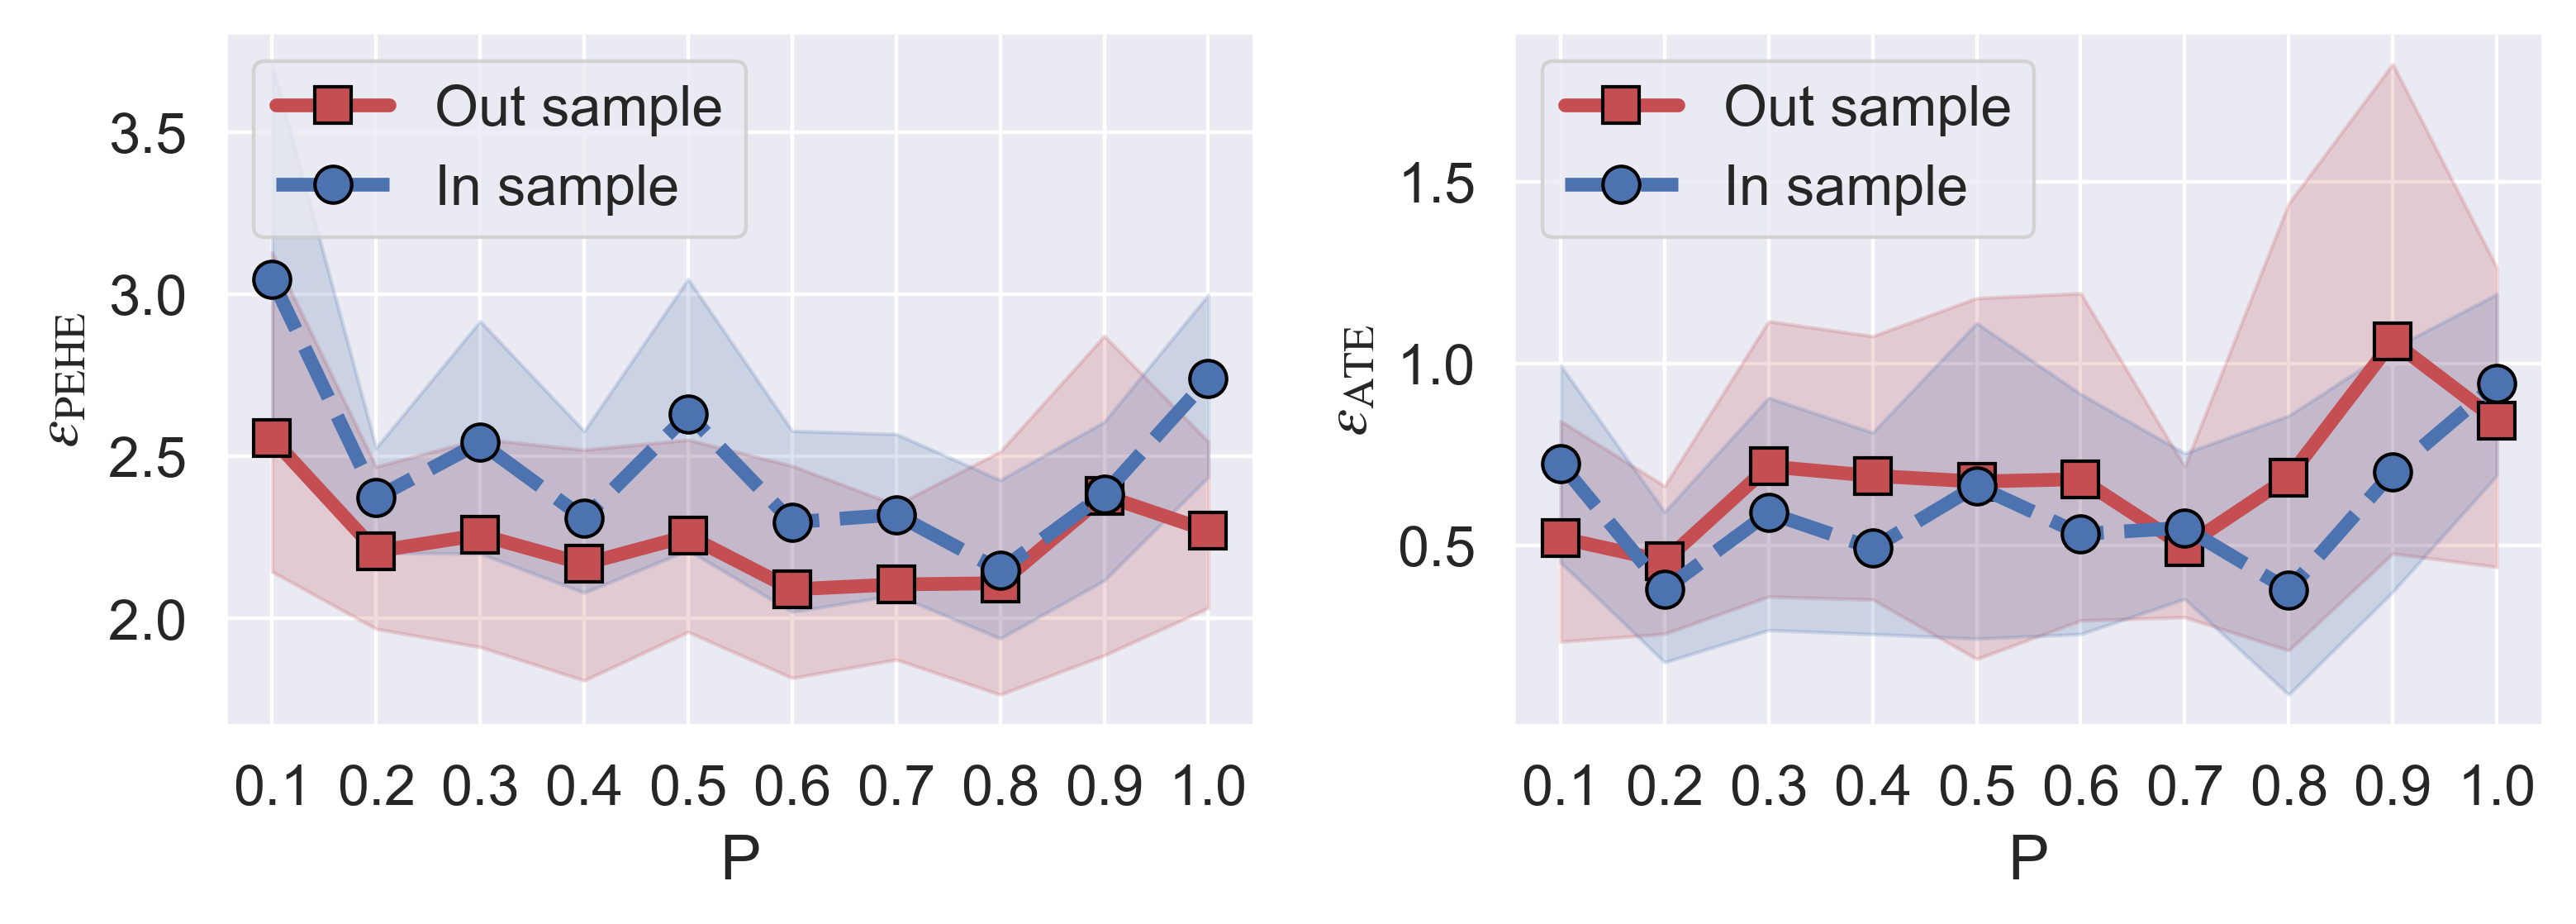

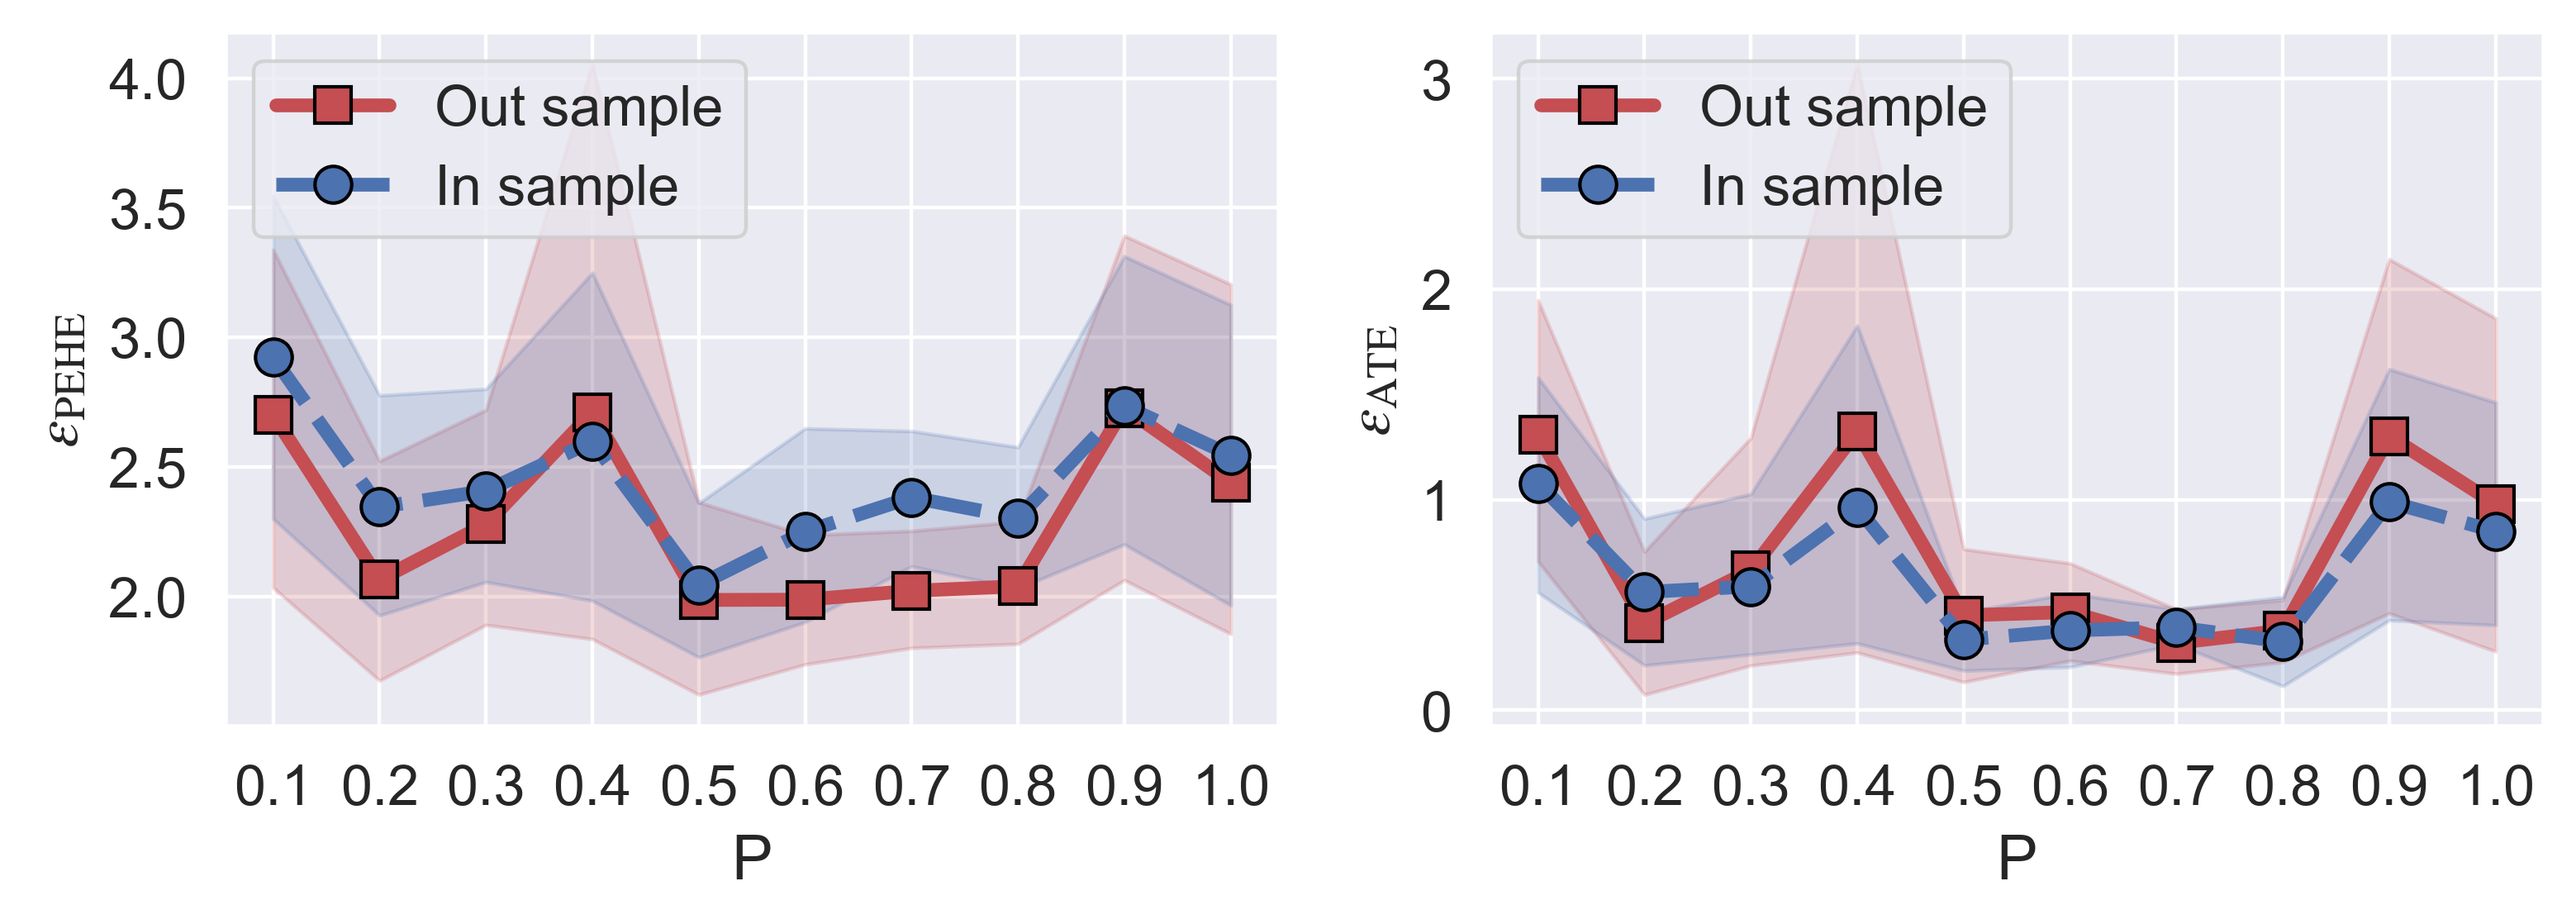

In [6]:
x_column = 'pca_ratio'
data = load_data(['./exp_hyperparam/ACIC/ylearner_MLP'])
data.loc[:, x_column] = data[x_column].astype(float)
data['labda'] = data['lambda'] 

data_1 = data.sort_values(by=x_column).query("labda==1.0 and fgw_alpha==0.3 and ot_scale == 0.1")
data_2 = data.sort_values(by=x_column).query("labda==1.0 and fgw_alpha==0.7 and ot_scale == 0.1")
plot(data_1, figure_name=f'figure_{x_column}_1', x=x_column, x_name='P', ytick1=None, ytick2=None, ypad2=0.02)
plot(data_2, figure_name=f'figure_{x_column}_2', x=x_column, x_name='P', ytick1=None, ytick2=None, ypad2=0.02)

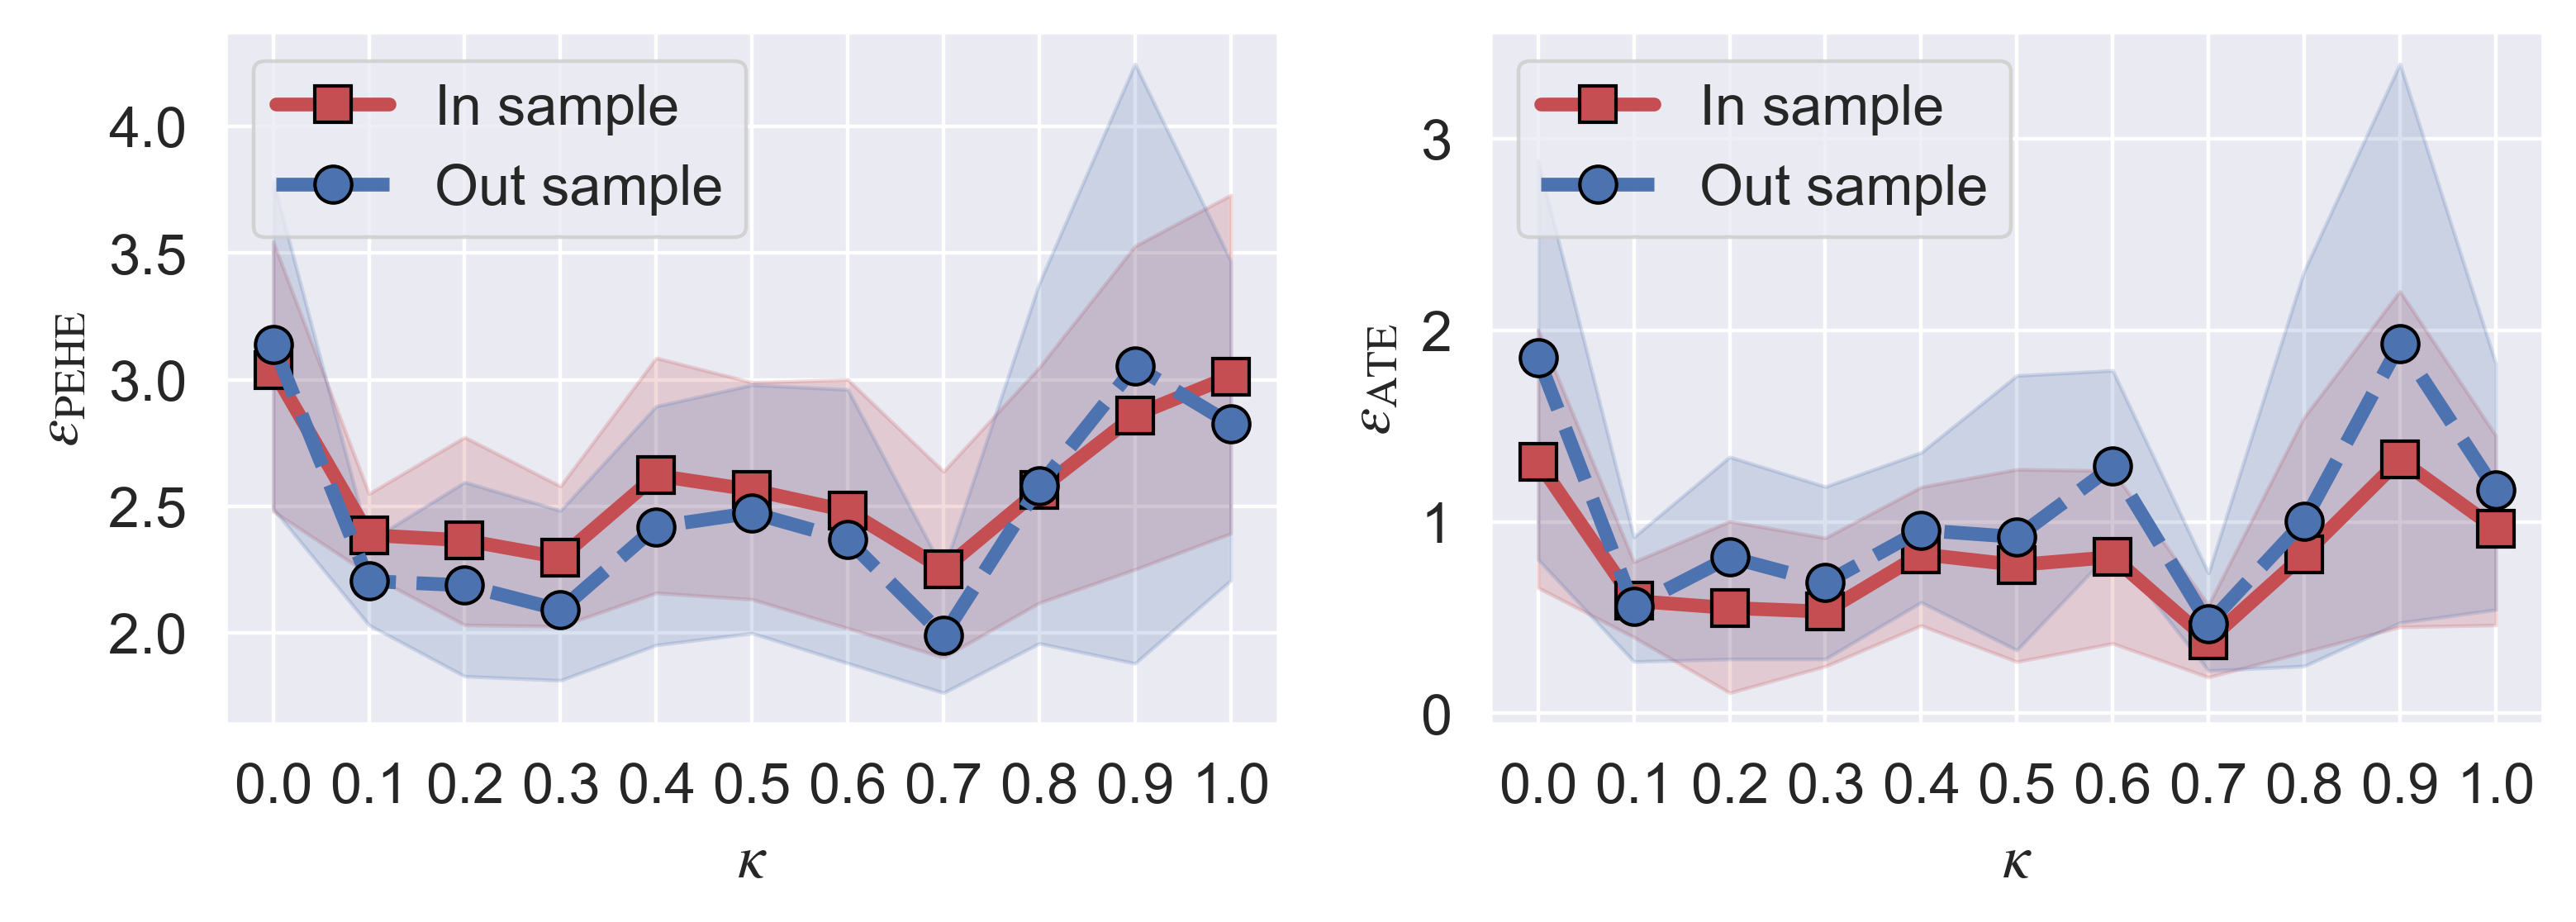

In [7]:
x_column = 'fgw_alpha'
data = load_data(['./exp_hyperparam/ACIC/ylearner_MLP'])
data.loc[:, x_column] = data[x_column].astype(float)
data['labda'] = data['lambda'] 

data_1 = data.sort_values(by=x_column).query("labda==1.0 and pca_ratio==0.5 and ot_scale == 0.1")
data_2 = data.sort_values(by=x_column).query("labda==1.0 and pca_ratio==0.6 and ot_scale == 0.1")
# plot(data_1, figure_name=f'figure_{x_column}_1', x=x_column, x_name='$\kappa$', ytick1=None, ytick2=None, ypad2=0.02)
plot(data_2, figure_name=f'figure_{x_column}_2', x=x_column, x_name='$\kappa$', ytick1=None, ytick2=None, ypad2=0.02)

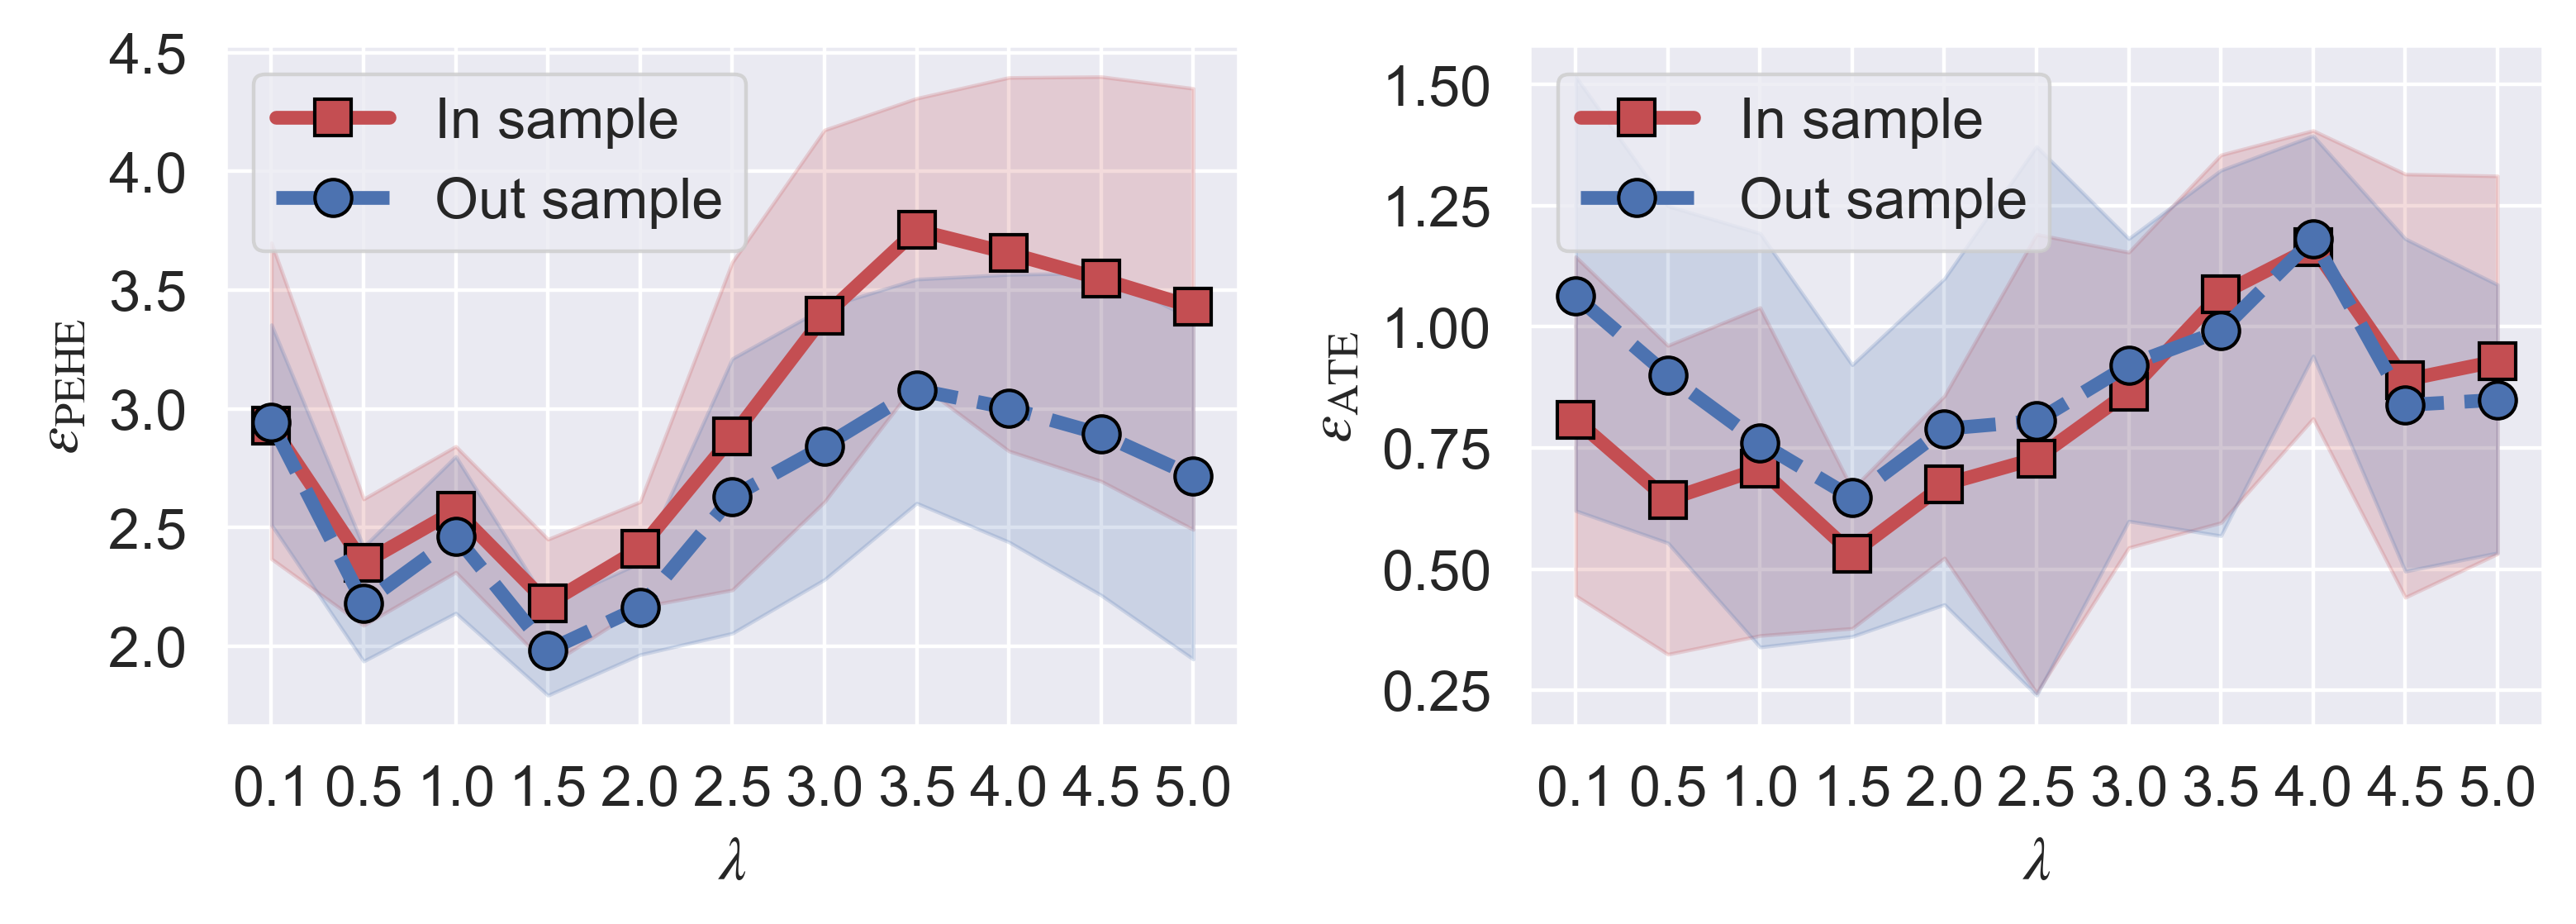

In [8]:
x_column = 'labda'
data = load_data(['./exp_hyperparam/ACIC/ylearner_MLP'])
data['labda'] = data['lambda'] 
data.loc[:, x_column] = data[x_column].astype(float)

data_1 = data.sort_values(by=x_column).query("fgw_alpha==0.3 and pca_ratio==0.7 and ot_scale == 0.1 and labda < 4.5")
data_2 = data.sort_values(by=x_column).query("fgw_alpha==0.5 and pca_ratio==0.7 and ot_scale == 0.1")
# plot(data_1, figure_name=f'figure_{x_column}_1', x=x_column, x_name='$\kappa$', ytick1=None, ytick2=None, ypad2=0.02)
plot(data_2, figure_name=f'figure_{x_column}_2', x=x_column, x_name='$\lambda$', ytick1=None, ytick2=None, ypad2=0.02)